# AcneVision: Deteksi & Penghitungan Lesi Jerawat dengan YOLOv8

Notebook ringkasan seluruh development model: **dataset → preprocessing → augmentasi → training →
evaluasi → counting → inferensi**. Fokus pada tiga varian yang dibandingkan di presentasi:

| Varian | Isi | Inferensi |
|---|---|---|
| **B0 baseline** | YOLOv8l @960, setelan default Ultralytics | plain |
| **E3 tuned** | YOLOv8l @960, augmentasi + hyperparameter disesuaikan untuk lesi kecil | plain |
| **E4 + SAHI** | E3 di-fine-tune pada tile 2×2 resolusi penuh | SAHI (slice 1728 → 960) |

Bagian 5.6 menambahkan kontrol **E5** (config E4, bobot awal B0) untuk memisahkan efek tuning E3 dan
fine-tune tile (desain 2×2).

**Catatan eksekusi**
- Notebook ini **hanya membaca hasil yang sudah ada** (`runs/`, `docs/report/`, `data/`), jadi bisa
  dijalankan di CPU. Training, evaluasi, dan prediksi dijalankan lewat `scripts/*.py`.
- Sel inferensi langsung (GPU) di bagian 8 nonaktif secara default (`RUN_INFERENCE = False`).
- Semua metrik: split **test** (121 gambar), `imgsz=960`, matching IoU 0.5, threshold conf dipilih di
  **val** (MAE counting minimum). Sumber: `runs/eval/<run>/metrics.json`.

## 0. Setup

In [1]:
import json, sys, warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import yaml
from PIL import Image
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "scripts"), str(ROOT / "scripts" / "data")]
from analysis import load_gt_boxes          # definisi GT identik dengan evaluate.py
from common import MAX_DET, severity_from_name
from preprocess import tile_windows        # logika tiling identik dengan dataset E4

%matplotlib inline
import matplotlib.pyplot as plt            # analysis.py memaksa backend Agg; inline dipulihkan di atas

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
plt.rcParams.update({
    "figure.dpi": 80, "font.size": 10, "axes.grid": True, "grid.color": "#e4e3df",
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c8c8c8", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
DATA, RUNS, REPORT = ROOT / "data", ROOT / "runs", ROOT / "docs" / "report"
TEAL, TEAL2, TEAL3 = "#0b2b33", "#1c8c99", "#8fc9cf"

# Tiga varian utama. Warna melekat pada varian (palet tervalidasi skill dataviz, sama dengan deck).
# Urutan grafik E4S → B0 → E3: pasangan pink-oranye tidak bersebelahan (lolos uji CVD).
VARS = {
    "B0":  dict(label="B0 baseline", det="yolov8l_960_default", eval="yolov8l_960_default",
                pred="yolov8l_960_default_plain", color="#2a78d6"),
    "E3":  dict(label="E3 tuned", det="yolov8l_960", eval="yolov8l_960",
                pred="yolov8l_960_plain", color="#eb6834"),
    "E4S": dict(label="E4 + SAHI", det="yolov8l_960_tiles2_ft", eval="yolov8l_960_tiles2_ft_sahi1728",
                pred="yolov8l_960_tiles2_ft_sahi", color="#e87ba4"),
}
TABLE_ORDER, CHART_ORDER = ["B0", "E3", "E4S"], ["E4S", "B0", "E3"]
for v in VARS.values():
    v["m"] = json.loads((RUNS / "eval" / v["eval"] / "metrics.json").read_text())

def show_img(ax, img_bgr, title=None, max_side=1400):
    # Tampilkan gambar BGR yang diperkecil (foto asli ±3456 px, terlalu berat bila disimpan utuh)
    s = max_side / max(img_bgr.shape[:2])
    if s < 1:
        img_bgr = cv2.resize(img_bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    ax.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)); ax.axis("off")
    if title:
        ax.set_title(title, fontsize=10)

def draw_gt(img, boxes, color=(60, 200, 60), lw=None):
    lw = lw or max(2, round(max(img.shape[:2]) / 450))      # tetap terlihat setelah gambar diperkecil
    for x1, y1, x2, y2 in boxes.astype(int):
        cv2.rectangle(img, (x1, y1), (x2, y2), color, lw)
    return img

print("ROOT:", ROOT)

ROOT: D:\bintang\acnevision


### Ringkasan semua varian yang pernah dievaluasi
Tabel lengkap dari `docs/report/summary.json` (dibuat `scripts/report.py`). Tiga varian utama
dicetak tebal di bagian selanjutnya; varian lain (E3+TTA, E3+SAHI, B0+SAHI) adalah ablation.

In [2]:
summary = pd.DataFrame(json.loads((REPORT / "summary.json").read_text())).set_index("Varian")
summary

,mAP50 (Ultralytics),mAP50-95,AP50 (internal),mAP50-95 (internal),conf (val),Precision,Recall,F1,TP,FP,FN,FP lokalisasi,MAE,RMSE,Bias,Pearson r,Latency ms,Inference ms (Ultralytics)
Varian,,,,,,,,,,,,,,,,,,
B0 baseline default,0.4997,0.1931,0.4994,0.1923,0.26,0.5717,0.4765,0.5198,1671,1252,1836,657,9.27,25.99,-4.83,0.8604,69.2,42.98
E3 aug+hyp tuned,0.4980,0.1914,0.4909,0.1863,0.21,0.5445,0.4882,0.5148,1712,1432,1795,866,8.69,20.18,-3.00,0.9096,69.9,43.80
E3 + TTA,0.4746,0.1771,0.4671,0.1810,0.28,0.5302,0.4534,0.4888,1590,1409,1917,996,8.98,19.56,-4.20,0.9194,113.9,90.44
E3 + SAHI,NaN,NaN,0.5370,0.1945,0.23,0.5925,0.5341,0.5618,1873,1288,1634,494,8.33,17.97,-2.86,0.9457,639.1,NaN
E4 tile-FT + SAHI,NaN,NaN,0.5499,0.2046,0.22,0.6112,0.5361,0.5712,1880,1196,1627,500,8.29,18.66,-3.56,0.9425,625.6,NaN
B0 + SAHI,NaN,NaN,0.5113,0.1903,0.34,0.5685,0.4876,0.5249,1710,1298,1797,424,10.04,24.92,-4.12,0.8912,641.0,NaN
E5 tile-FT(B0) + SAHI,NaN,NaN,0.5333,0.1919,0.22,0.5982,0.5158,0.5540,1809,1215,1698,516,8.83,19.53,-3.99,0.9359,631.4,NaN


## 1. Dataset ACNE04-v2

- Foto wajah resolusi tinggi dengan anotasi lesi, dikelompokkan dalam 4 level keparahan Hayashi
  (prefix nama file `levle0_` … `levle3_`).
- Anotasi asli berupa **lingkaran** (cx, cy, r), dikonversi ke bounding box YOLO satu kelas `acne`
  oleh `scripts/data/convert_to_yolo.py`. Split 80/10/10 dengan seed 42.

In [3]:
rows = []
for split in ["train", "val", "test"]:
    for lbl in sorted((DATA / "labels" / split).glob("*.txt")):
        img = DATA / "images" / split / f"{lbl.stem}.jpg"
        W, H = Image.open(img).size                        # hanya membaca header JPEG
        lines = [l.split() for l in lbl.read_text().splitlines() if l.strip()]
        wh = np.array([[float(l[3]) * W, float(l[4]) * H] for l in lines]).reshape(-1, 2)
        rows.append({"split": split, "image": img.name, "level": severity_from_name(img.name),
                     "W": W, "H": H, "n_lesi": len(lines),
                     # sisi lesi setelah letterbox ke 960 px (sisi terpanjang gambar = 960)
                     "lesi_px960": wh.max(axis=1) * 960 / max(W, H)})
ds = pd.DataFrame(rows)

per_split = ds.pivot_table(index="level", columns="split", values="image", aggfunc="count")[["train", "val", "test"]]
per_split.loc["total"] = per_split.sum()
lesi = ds.groupby("split")["n_lesi"].agg(["sum", "mean", "median", "max"])[["sum", "mean", "median", "max"]]
display(per_split.rename_axis("jumlah gambar per level"))
display(lesi.rename(columns={"sum": "total lesi", "mean": "rata-rata/gambar"}).loc[["train", "val", "test"]])
W0, H0 = ds.groupby(["W", "H"]).size().idxmax()
side = ds[["W", "H"]].max(axis=1)
print(f"Resolusi paling umum: {W0}×{H0} px | sisi terpanjang: {side.min()}–{side.max()} px (median {side.median():.0f})")

split,train,val,test
jumlah gambar per level,,,
0,371,48,51
1,468,52,59
2,105,18,10
3,19,2,1
total,963,120,121


,total lesi,rata-rata/gambar,median,max
split,,,,
train,25521,26.5016,19.0,232
val,3366,28.0500,17.0,215
test,3507,28.9835,21.0,434


Resolusi paling umum: 3112×3456 px | sisi terpanjang: 436–5184 px (median 3456)


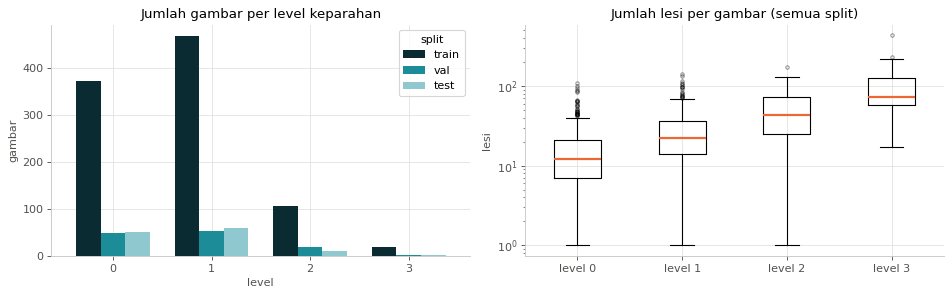

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
per_split.drop("total").plot.bar(ax=ax[0], color=[TEAL, TEAL2, TEAL3], width=0.75, rot=0)
ax[0].set(title="Jumlah gambar per level keparahan", xlabel="level", ylabel="gambar")
data_box = [ds.loc[ds.level == l, "n_lesi"] for l in range(4)]
ax[1].boxplot(data_box, labels=[f"level {l}" for l in range(4)], showfliers=True,
              medianprops=dict(color="#eb6834", lw=2), flierprops=dict(ms=3, alpha=.4))
ax[1].set(title="Jumlah lesi per gambar (semua split)", ylabel="lesi"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()

**Tantangan utama: lesi sangat kecil.** Setelah foto (±3456 px) di-resize ke input 960 px,
sebagian besar lesi hanya berukuran belasan piksel, di bawah batas nyaman detektor (≈16 px,
stride terkecil YOLOv8 = 8 px).

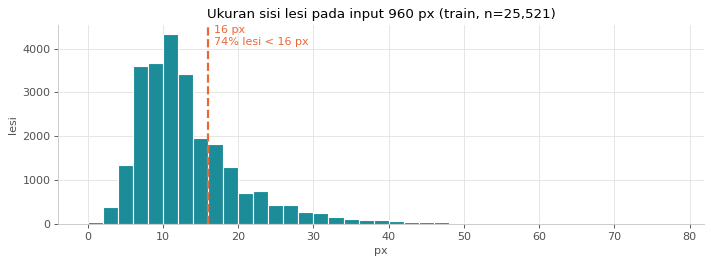

median 11.7 px | P10 6.7 | P90 22.8


In [5]:
sizes = np.concatenate(ds.loc[ds.split == "train", "lesi_px960"].to_numpy())
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(sizes, bins=np.arange(0, 80, 2), color=TEAL2, edgecolor="white")
ax.axvline(16, color="#eb6834", lw=2, ls="--")
ax.text(16.8, ax.get_ylim()[1] * 0.9, f"16 px\n{(sizes < 16).mean():.0%} lesi < 16 px", color="#eb6834")
ax.set(title=f"Ukuran sisi lesi pada input 960 px (train, n={len(sizes):,})", xlabel="px", ylabel="lesi")
plt.tight_layout(); plt.show()
print(f"median {np.median(sizes):.1f} px | P10 {np.percentile(sizes, 10):.1f} | P90 {np.percentile(sizes, 90):.1f}")

### Contoh gambar asli + ground truth (satu per level, split train)

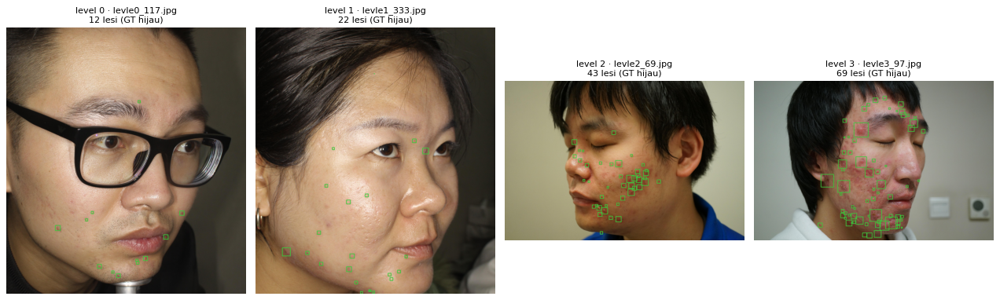

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for lvl, ax in enumerate(axes):
    r = ds[(ds.split == "train") & (ds.level == lvl)].sort_values("n_lesi").iloc[len(ds[(ds.split == "train") & (ds.level == lvl)]) // 2]
    img = cv2.imread(str(DATA / "images" / "train" / r.image))
    gt = load_gt_boxes(DATA / "labels" / "train" / f"{Path(r.image).stem}.txt", img.shape[1], img.shape[0])
    show_img(ax, draw_gt(img, gt), f"level {lvl} · {r.image}\n{len(gt)} lesi (GT hijau)", max_side=900)
plt.tight_layout(); plt.show()

## 2. Preprocessing

### 2.1 Lingkaran → bounding box
Anotasi lingkaran diubah ke kotak yang melingkupinya: `x1 = cx − r`, `x2 = cx + r` (di-clip ke batas
gambar). File anotasi mentah (`data/raw/`) tidak disimpan di repo, sehingga lingkaran di bawah
**direkonstruksi** dari kotak (r = w/2) sebagai ilustrasi; untuk kotak yang tidak ter-clip hasilnya identik.

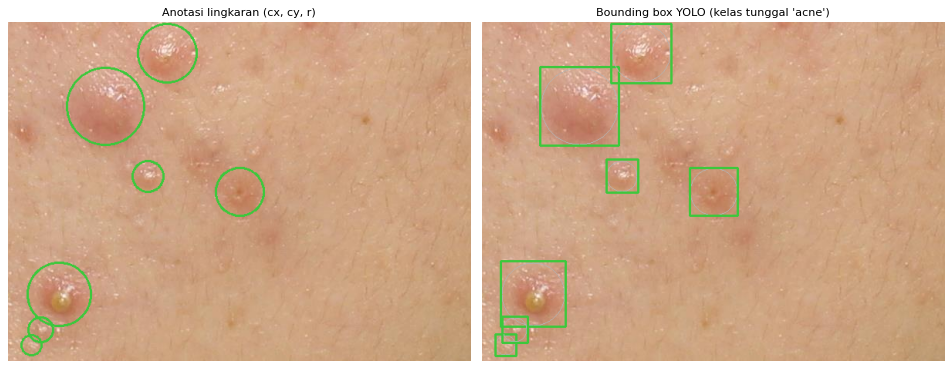

In [7]:
name = "levle2_118.jpg"
img = cv2.imread(str(DATA / "images" / "test" / name))
gt = load_gt_boxes(DATA / "labels" / "test" / f"{Path(name).stem}.txt", img.shape[1], img.shape[0])
c = gt[len(gt) // 2]; cx, cy = (c[:2] + c[2:]) / 2
x0, y0 = int(max(cx - 300, 0)), int(max(cy - 220, 0))
crop = img[y0:y0 + 440, x0:x0 + 600].copy()
circ, box = crop.copy(), crop.copy()
for x1, y1, x2, y2 in gt - [x0, y0, x0, y0]:
    cv2.circle(circ, (int((x1 + x2) / 2), int((y1 + y2) / 2)), int((x2 - x1) / 2), (60, 200, 60), 2)
    cv2.circle(box, (int((x1 + x2) / 2), int((y1 + y2) / 2)), int((x2 - x1) / 2), (180, 180, 180), 1)
    cv2.rectangle(box, (int(x1), int(y1)), (int(x2), int(y2)), (60, 200, 60), 2)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
show_img(ax[0], circ, "Anotasi lingkaran (cx, cy, r)"); show_img(ax[1], box, "Bounding box YOLO (kelas tunggal 'acne')")
plt.tight_layout(); plt.show()

### 2.2 Resize ke input 960 px: informasi yang hilang
YOLO me-*letterbox* gambar sehingga sisi terpanjang = 960 px (skala ≈ 0,28 untuk foto 3456 px).
Area yang sama pada resolusi asli vs setelah resize:

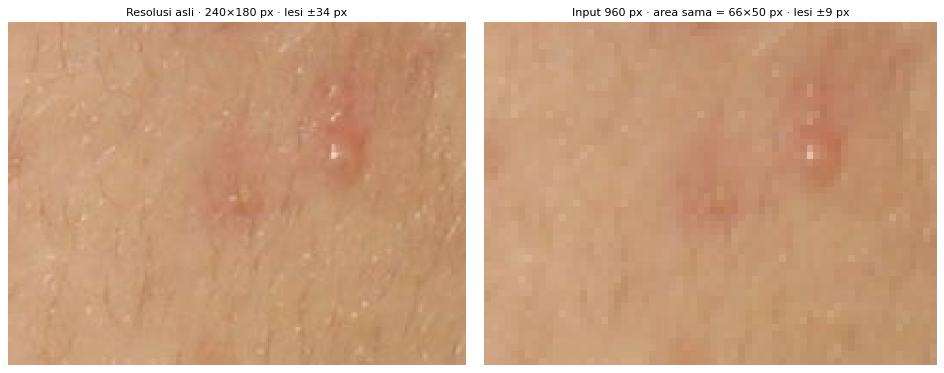

In [8]:
s = 960 / max(img.shape[:2])
small = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
# Potongan kecil di sekitar lesi terkecil agar efek resize terlihat
wh = gt[:, 2] - gt[:, 0]
c = gt[np.argsort(wh)[len(wh) // 4]]; cx, cy = (c[:2] + c[2:]) / 2
X0, Y0, CW, CH = int(cx - 120), int(cy - 90), 240, 180
crop_big = img[Y0:Y0 + CH, X0:X0 + CW]
crop_small = small[int(Y0 * s):int((Y0 + CH) * s), int(X0 * s):int((X0 + CW) * s)]
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, im, t in [(ax[0], crop_big, f"Resolusi asli · {CW}×{CH} px · lesi ±{c[2] - c[0]:.0f} px"),
                 (ax[1], crop_small, f"Input 960 px · area sama = {crop_small.shape[1]}×{crop_small.shape[0]} px · lesi ±{(c[2] - c[0]) * s:.0f} px")]:
    a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), interpolation="nearest"); a.axis("off"); a.set_title(t, fontsize=10)
plt.tight_layout(); plt.show()

### 2.3 Tiling 2×2 untuk fine-tuning E4 (`scripts/data/preprocess.py --grid 2 --overlap 0.1`)
Gambar train/val dipotong menjadi 4 tile beroverlap 10% pada resolusi asli; tiap tile lalu di-resize ke
960 sehingga lesi tampil ≈2× lebih besar. Bbox di-clip ke tile dan dibuang bila < 50% luasnya terlihat.
Dataset tile (`data_tiles2/`) = gambar utuh + tile; **test tidak di-tile**.

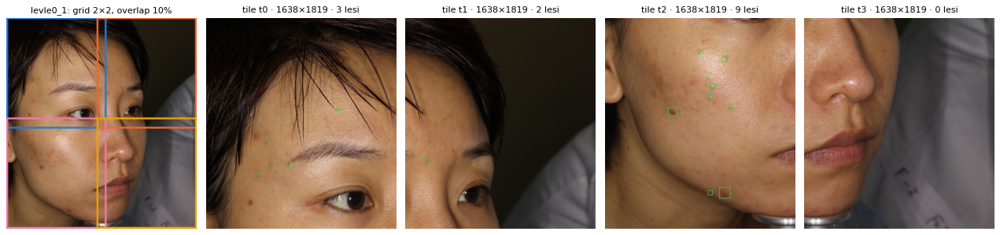

data_tiles2/train: 4815 gambar (= 963 gambar utuh × (1 + 4 tile))


In [9]:
stem = "levle0_1"
full = cv2.imread(str(ROOT / "data_tiles2" / "images" / "train" / f"{stem}.jpg"))
H, W = full.shape[:2]
wins = tile_windows(W, H, grid=2, overlap=0.1)
vis = full.copy()
colors = [(214, 120, 42), (52, 104, 235), (164, 123, 232), (0, 161, 237)]
for (x1, y1, x2, y2), col in zip(wins, colors):
    cv2.rectangle(vis, (x1 + 15, y1 + 15), (x2 - 15, y2 - 15), col, 30)
fig = plt.figure(figsize=(16, 5.5))
show_img(fig.add_subplot(1, 5, 1), vis, f"{stem}: grid 2×2, overlap 10%", max_side=800)
for k in range(4):
    t = cv2.imread(str(ROOT / "data_tiles2" / "images" / "train" / f"{stem}_t{k}.jpg"))
    tb = load_gt_boxes(ROOT / "data_tiles2" / "labels" / "train" / f"{stem}_t{k}.txt", t.shape[1], t.shape[0])
    show_img(fig.add_subplot(1, 5, k + 2), draw_gt(t, tb), f"tile t{k} · {t.shape[1]}×{t.shape[0]} · {len(tb)} lesi", max_side=800)
plt.tight_layout(); plt.show()
n_tiles = len(list((ROOT / "data_tiles2" / "images" / "train").glob("*.jpg")))
print(f"data_tiles2/train: {n_tiles} gambar (= {n_tiles // 5} gambar utuh × (1 + 4 tile))")

### 2.4 SAHI saat inferensi (E4 + SAHI)
Gambar test dipotong menjadi slice 1728×1728 px (overlap 0,2); tiap slice di-resize ke 960 lalu
diprediksi, hasilnya digabung dengan NMS (IoU 0,5). Konsisten dengan skala tile saat fine-tuning.

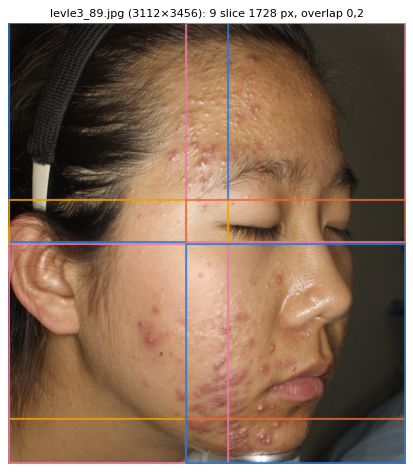

In [10]:
from sahi.slicing import get_slice_bboxes
name = "levle3_89.jpg"
t = cv2.imread(str(DATA / "images" / "test" / name))
sl = get_slice_bboxes(t.shape[0], t.shape[1], 1728, 1728, overlap_height_ratio=0.2, overlap_width_ratio=0.2)
vis = t.copy()
for i, (x1, y1, x2, y2) in enumerate(sl):
    cv2.rectangle(vis, (x1 + 8, y1 + 8), (x2 - 8, y2 - 8), colors[i % 4], 12)
fig, ax = plt.subplots(figsize=(7, 6))
show_img(ax, vis, f"{name} ({t.shape[1]}×{t.shape[0]}): {len(sl)} slice 1728 px, overlap 0,2", max_side=900)
plt.tight_layout(); plt.show()

## 3. Augmentasi

Augmentasi dijalankan on-the-fly oleh Ultralytics saat training. Perbandingan setelan B0 (default) vs
E3/E4 (disesuaikan, dari `runs/detect/<run>/args.yaml`):

In [11]:
AUG_KEYS = ["mosaic", "close_mosaic", "mixup", "copy_paste", "fliplr", "flipud", "degrees",
            "translate", "scale", "hsv_h", "hsv_s", "hsv_v"]
args = {k: yaml.safe_load((RUNS / "detect" / VARS[k]["det"] / "args.yaml").read_text()) for k in ["B0", "E3", "E4S"]}
aug = pd.DataFrame({VARS[k]["label"].replace(" + SAHI", " (fine-tune)"): {a: args[k][a] for a in AUG_KEYS} for k in args})
aug

,B0 baseline,E3 tuned,E4 (fine-tune)
mosaic,1.000,1.000,1.000
close_mosaic,10.000,10.000,3.000
mixup,0.000,0.100,0.100
copy_paste,0.000,0.300,0.000
fliplr,0.500,0.500,0.500
flipud,0.000,0.500,0.500
degrees,0.000,10.000,10.000
translate,0.100,0.100,0.100
scale,0.500,0.500,0.500
hsv_h,0.015,0.015,0.015


- **flipud & rotasi ±10°**: wajah boleh terbalik/miring karena lesi tidak memiliki orientasi.
- **mixup 0,1**: memperkaya konteks kulit tanpa menambah label palsu berlebihan.
- **copy_paste** hanya aktif untuk label segmentasi; dengan label bbox efeknya *no-op*, sehingga diset 0.

### 3.1 Efek tiap augmentasi (ilustrasi pada nilai maksimum)

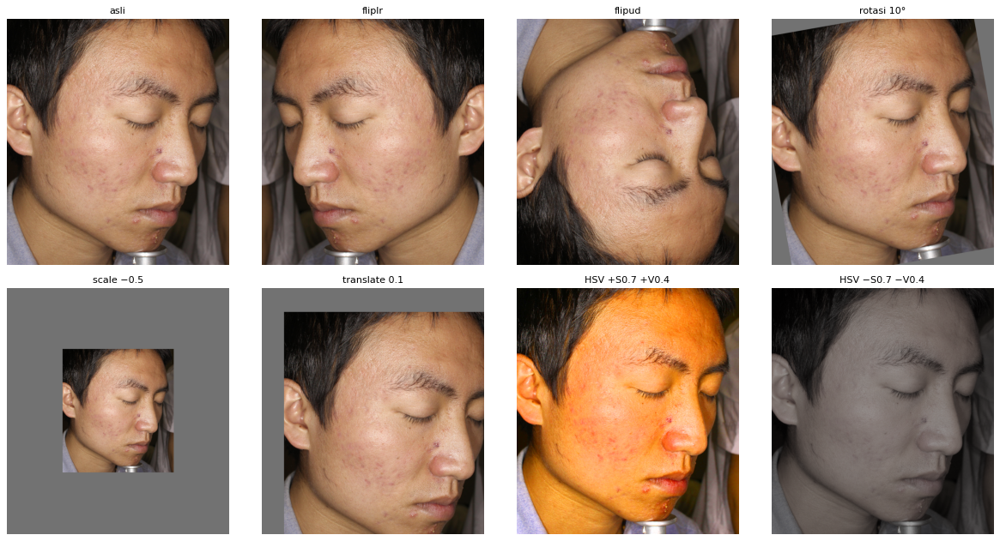

In [12]:
name = "levle1_288.jpg"
base = cv2.imread(str(DATA / "images" / "test" / name))
s = 900 / max(base.shape[:2]); base = cv2.resize(base, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
h, w = base.shape[:2]
def hsv(img, dh, ds_, dv):
    x = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    x[..., 0] = (x[..., 0] + dh * 180) % 180; x[..., 1] *= 1 + ds_; x[..., 2] *= 1 + dv
    return cv2.cvtColor(np.clip(x, 0, 255).astype(np.uint8), cv2.COLOR_HSV2BGR)
e3 = args["E3"]
demos = {
    "asli": base,
    "fliplr": cv2.flip(base, 1),
    "flipud": cv2.flip(base, 0),
    f"rotasi {e3['degrees']:.0f}°": cv2.warpAffine(base, cv2.getRotationMatrix2D((w / 2, h / 2), e3["degrees"], 1), (w, h), borderValue=(114, 114, 114)),
    f"scale −{e3['scale']}": cv2.warpAffine(base, cv2.getRotationMatrix2D((w / 2, h / 2), 0, 1 - e3["scale"]), (w, h), borderValue=(114, 114, 114)),
    f"translate {e3['translate']}": cv2.warpAffine(base, np.float32([[1, 0, e3["translate"] * w], [0, 1, e3["translate"] * h]]), (w, h), borderValue=(114, 114, 114)),
    f"HSV +S{e3['hsv_s']} +V{e3['hsv_v']}": hsv(base, e3["hsv_h"], e3["hsv_s"], e3["hsv_v"]),
    f"HSV −S{e3['hsv_s']} −V{e3['hsv_v']}": hsv(base, -e3["hsv_h"], -e3["hsv_s"], -e3["hsv_v"]),
}
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, (k, im) in zip(axes.ravel(), demos.items()):
    show_img(ax, im, k)
plt.tight_layout(); plt.show()

### 3.2 Sampel nyata dari pipeline augmentasi Ultralytics (setelan E3)
Diambil langsung dari `YOLODataset` dengan hyperparameter E3 (mosaic 4 gambar, mixup, flip, rotasi,
HSV, letterbox 960). Kotak hijau = label setelah augmentasi. CPU saja.

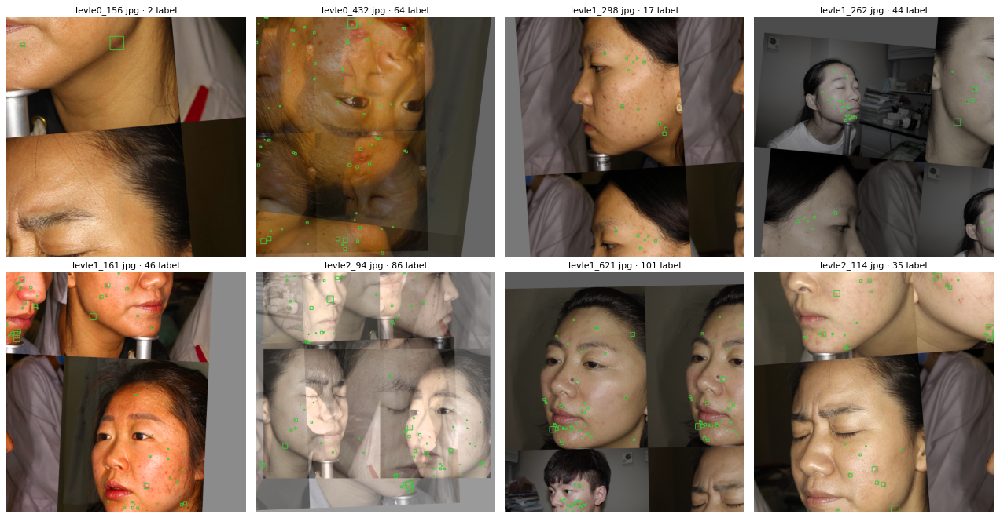

In [13]:
from ultralytics.cfg import get_cfg
from ultralytics.data import build_yolo_dataset
from ultralytics.data.utils import check_det_dataset
from ultralytics.utils import LOGGER
import random, torch
LOGGER.setLevel(40)
random.seed(0); np.random.seed(0); torch.manual_seed(0)
over = {k: v for k, v in args["E3"].items() if k in AUG_KEYS or k in ("imgsz",)}
cfg = get_cfg(overrides=over)
data_cfg = check_det_dataset(str(DATA / "data.yaml"))
train_ds = build_yolo_dataset(cfg, data_cfg["train"], batch=4, data=data_cfg, mode="train")
fig, axes = plt.subplots(2, 4, figsize=(16, 8.4))
for ax, idx in zip(axes.ravel(), random.sample(range(len(train_ds)), 8)):
    smp = train_ds[idx]
    im = np.ascontiguousarray(smp["img"].permute(1, 2, 0).numpy()[..., ::-1])   # RGB tensor → BGR
    S = im.shape[0]
    b = smp["bboxes"].numpy() * S
    xyxy = np.c_[b[:, 0] - b[:, 2] / 2, b[:, 1] - b[:, 3] / 2, b[:, 0] + b[:, 2] / 2, b[:, 1] + b[:, 3] / 2]
    show_img(ax, draw_gt(im.copy(), xyxy, lw=2), f"{Path(smp['im_file']).name} · {len(b)} label", max_side=960)
plt.tight_layout(); plt.show()

Batch training pertama yang disimpan Ultralytics saat training E3 (`runs/detect/yolov8l_960/train_batch0.jpg`):

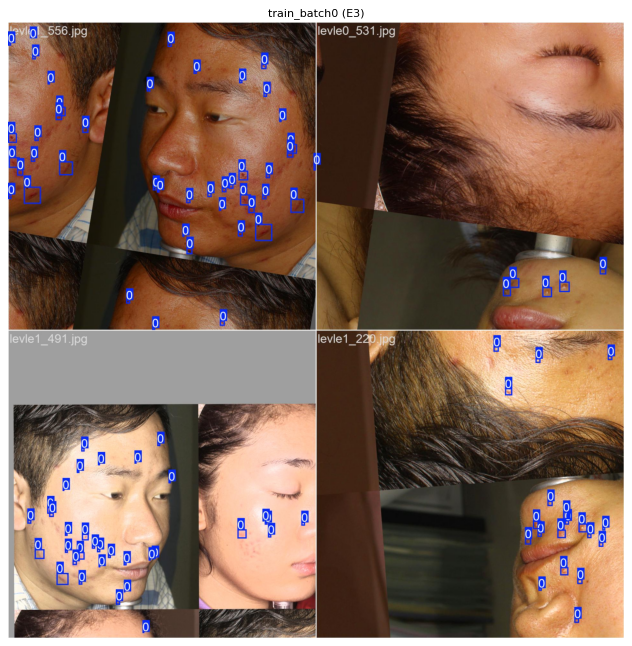

In [14]:
fig, ax = plt.subplots(figsize=(10, 10))
show_img(ax, cv2.imread(str(RUNS / "detect" / "yolov8l_960" / "train_batch0.jpg")), "train_batch0 (E3)")
plt.show()

## 4. Training

Semua model: YOLOv8l pretrained COCO, `imgsz=960`, `batch=4` (batas VRAM RTX 4060 8 GB), seed 42.
Satu eksperimen = satu config (`configs/*.yaml`).

In [15]:
KEYS = ["model", "data", "epochs", "patience", "optimizer", "lr0", "lrf", "cos_lr", "warmup_epochs",
        "box", "cls", "dfl", "imgsz", "batch"]
cfgtab = pd.DataFrame({VARS[k]["label"].replace(" + SAHI", " (fine-tune)"): {a: args[k][a] for a in KEYS} for k in args})
cfgtab

,B0 baseline,E3 tuned,E4 (fine-tune)
model,D:\bintang\acnevision\runs\detect\yolov8l_960_...,yolov8l.pt,D:\bintang\acnevision\runs\detect\yolov8l_960\...
data,D:\bintang\acnevision\data\data.yaml,D:\bintang\acnevision\data\data.yaml,D:\bintang\acnevision\data_tiles2\data.yaml
epochs,100,100,10
patience,100,25,10
optimizer,auto,AdamW,AdamW
lr0,0.01,0.001,0.0002
lrf,0.01,0.01,0.1
cos_lr,False,True,True
warmup_epochs,3.0,3,1
box,7.5,10.0,10.0


In [16]:
res = {}
for k in ["B0", "E3", "E4S"]:
    df = pd.read_csv(RUNS / "detect" / VARS[k]["det"] / "results.csv")
    df.columns = df.columns.str.strip()
    res[k] = df
info = pd.DataFrame({
    VARS[k]["label"].replace(" + SAHI", " (fine-tune)"): {
        "epoch dijalankan": int(df["epoch"].max()),
        "durasi (jam)": round(df["time"].max() / 3600, 2),
        "epoch mAP50-95 val terbaik": int(df.loc[df["metrics/mAP50-95(B)"].idxmax(), "epoch"]),
        "mAP50 val terbaik": round(df["metrics/mAP50(B)"].max(), 4),
        "mAP50-95 val terbaik": round(df["metrics/mAP50-95(B)"].max(), 4),
    } for k, df in res.items()})
info

,B0 baseline,E3 tuned,E4 (fine-tune)
epoch dijalankan,100.0000,100.0000,10.0000
durasi (jam),1.2500,2.2300,1.0800
epoch mAP50-95 val terbaik,57.0000,100.0000,10.0000
mAP50 val terbaik,0.4831,0.4668,0.4600
mAP50-95 val terbaik,0.1837,0.1855,0.1876


### 4.1 Kurva training B0 vs E3
Metrik val di sini dihitung Ultralytics selama training (split **val**, conf 0,001), bukan angka laporan akhir.

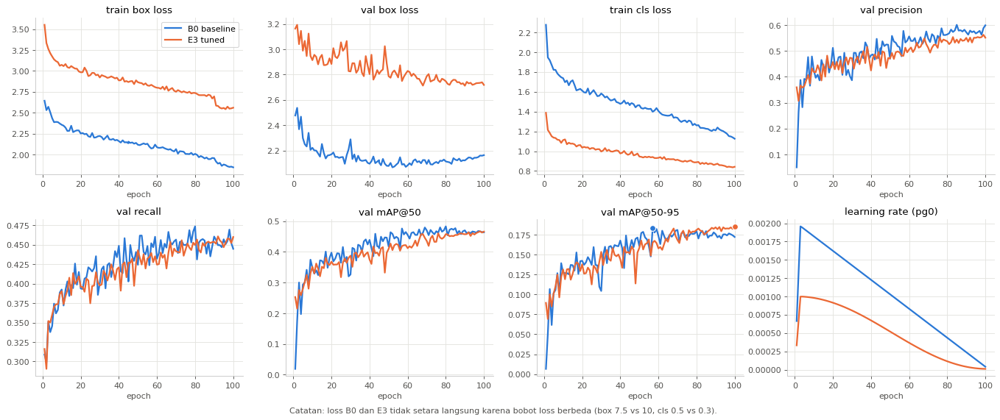

In [17]:
panels = [("train/box_loss", "train box loss"), ("val/box_loss", "val box loss"), ("train/cls_loss", "train cls loss"),
          ("metrics/precision(B)", "val precision"), ("metrics/recall(B)", "val recall"),
          ("metrics/mAP50(B)", "val mAP@50"), ("metrics/mAP50-95(B)", "val mAP@50-95"), ("lr/pg0", "learning rate (pg0)")]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, (col, title) in zip(axes.ravel(), panels):
    for k in ["B0", "E3"]:
        ax.plot(res[k]["epoch"], res[k][col], color=VARS[k]["color"], lw=2, label=VARS[k]["label"])
    if col.startswith("metrics/mAP50-95"):
        for k in ["B0", "E3"]:
            e = res[k].loc[res[k][col].idxmax()]
            ax.scatter(e["epoch"], e[col], color=VARS[k]["color"], s=50, zorder=3, edgecolor="white")
    ax.set(title=title, xlabel="epoch")
axes[0, 0].legend()
fig.text(0.5, -0.01, "Catatan: loss B0 dan E3 tidak setara langsung karena bobot loss berbeda (box 7.5 vs 10, cls 0.5 vs 0.3).",
         ha="center", color="#52514e")
plt.tight_layout(); plt.show()

### 4.2 Fine-tuning E4 pada tile
Val E4 berisi tile (`data_tiles2/val`), jadi angkanya **tidak sebanding** dengan kurva B0/E3 di atas.

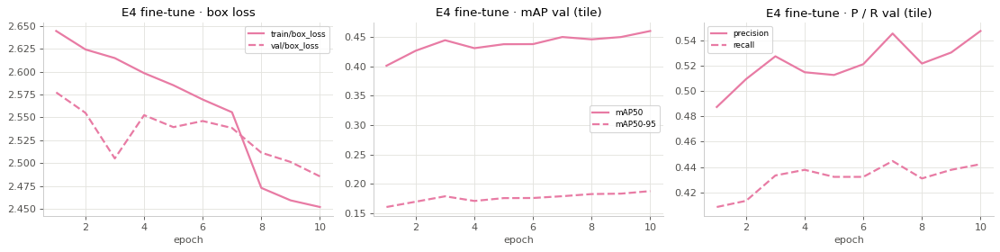

In [18]:
df = res["E4S"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, cols, title in [(axes[0], ["train/box_loss", "val/box_loss"], "box loss"),
                        (axes[1], ["metrics/mAP50(B)", "metrics/mAP50-95(B)"], "mAP val (tile)"),
                        (axes[2], ["metrics/precision(B)", "metrics/recall(B)"], "P / R val (tile)")]:
    for c, ls in zip(cols, ["-", "--"]):
        ax.plot(df["epoch"], df[c], color=VARS["E4S"]["color"], ls=ls, lw=2, label=c.replace("metrics/", "").replace("(B)", ""))
    ax.set(title=f"E4 fine-tune · {title}", xlabel="epoch"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Plot ringkas bawaan Ultralytics untuk E3 (`results.png`):

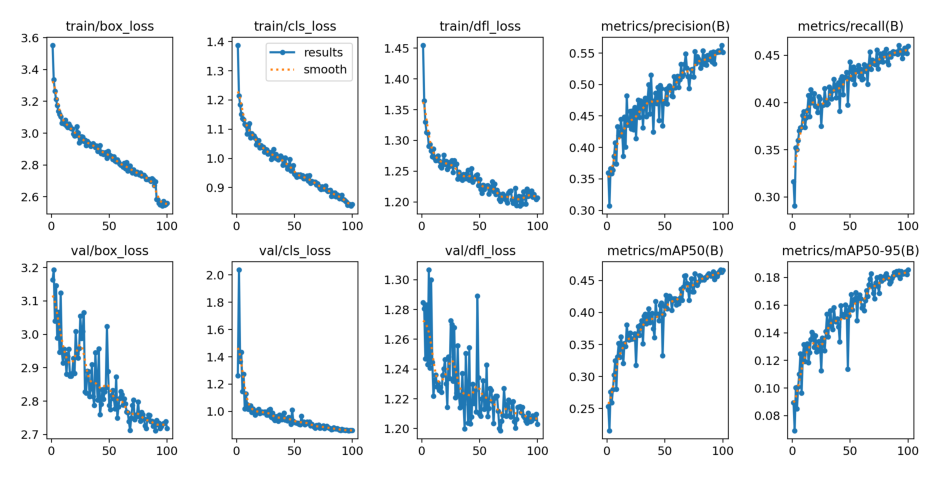

In [19]:
fig, ax = plt.subplots(figsize=(15, 7.5))
show_img(ax, cv2.imread(str(RUNS / "detect" / "yolov8l_960" / "results.png")), max_side=2400)
plt.show()

## 5. Evaluasi deteksi (split test)

Protokol (`scripts/evaluate.py`):
1. Prediksi semua gambar dengan conf 0,001, `max_det=1000`, `imgsz=960`.
2. Matching greedy per skor ke GT dengan IoU ≥ 0,5 → TP/FP/FN (definisi sama untuk plain dan SAHI).
3. **mAP@50** = AP internal (interpolasi 101 titik); **mAP@50-95** = rata-rata AP pada IoU 0,50:0,05:0,95.
   Untuk mode plain, selisih dengan Ultralytics ≤ 0,0002 (AP50) dan ≤ 0,0024 (mAP50-95).
4. **Precision/Recall/F1** dan confusion matrix pada threshold conf yang **dipilih di val**.

In [20]:
def row(k):
    m = VARS[k]["m"]; t = m["test_conf_val_tuned"]; d = t["detection"]
    ultra = m["detection_test_ultralytics"] or {}
    return {"conf (val)": m["conf_selected_on_val"], "Precision": d["precision"], "Recall": d["recall"],
            "F1": d["F1"], "mAP@50": m["ap50_test_internal"], "mAP@50-95": m["map50_95_test_internal"],
            "TP": d["TP"], "FP": d["FP"], "FN": d["FN"],
            "mAP@50 Ultralytics": ultra.get("mAP50"), "mAP@50-95 Ultralytics": ultra.get("mAP50_95")}
det = pd.DataFrame({VARS[k]["label"]: row(k) for k in TABLE_ORDER}).T
det.style.format(precision=4, na_rep="— (SAHI)").format({"TP": "{:.0f}", "FP": "{:.0f}", "FN": "{:.0f}"}) \
   .highlight_max(subset=["Precision", "Recall", "F1", "mAP@50", "mAP@50-95"], color="#fde2dd")

,conf (val),Precision,Recall,F1,mAP@50,mAP@50-95,TP,FP,FN,mAP@50 Ultralytics,mAP@50-95 Ultralytics
B0 baseline,0.260000,0.571700,0.476500,0.519800,0.499400,0.192300,1671,1252,1836,0.499700,0.193100
E3 tuned,0.210000,0.544500,0.488200,0.514800,0.490900,0.186300,1712,1432,1795,0.498000,0.191400
E4 + SAHI,0.220000,0.611200,0.536100,0.571200,0.549900,0.204600,1880,1196,1627,nan,nan


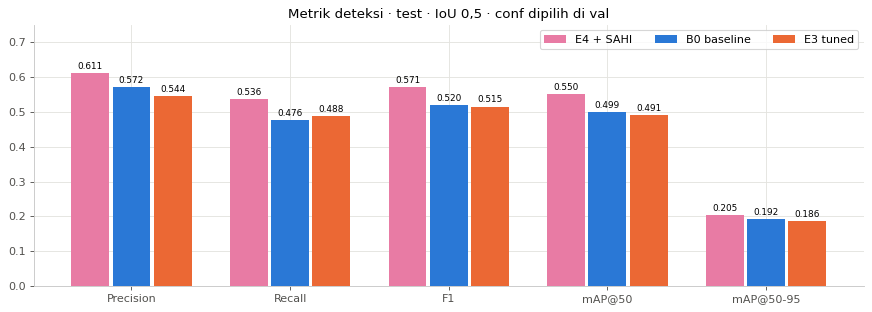

In [21]:
mets = ["Precision", "Recall", "F1", "mAP@50", "mAP@50-95"]
x = np.arange(len(mets)); bw = 0.26
fig, ax = plt.subplots(figsize=(11, 4))
for i, k in enumerate(CHART_ORDER):
    vals = det.loc[VARS[k]["label"], mets].astype(float).to_numpy()
    bars = ax.bar(x + (i - 1) * bw, vals, bw * 0.92, color=VARS[k]["color"], label=VARS[k]["label"])
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(x, mets); ax.set_ylim(0, 0.75); ax.legend(ncol=3, loc="upper right")
ax.set_title("Metrik deteksi · test · IoU 0,5 · conf dipilih di val")
plt.tight_layout(); plt.show()

### 5.1 Confusion matrix
Deteksi objek tidak punya *true negative* yang terdefinisi (area kulit yang benar tidak diprediksi
tidak terhitung), sehingga sel background-background ditandai N/A. Baris = prediksi, kolom = GT.

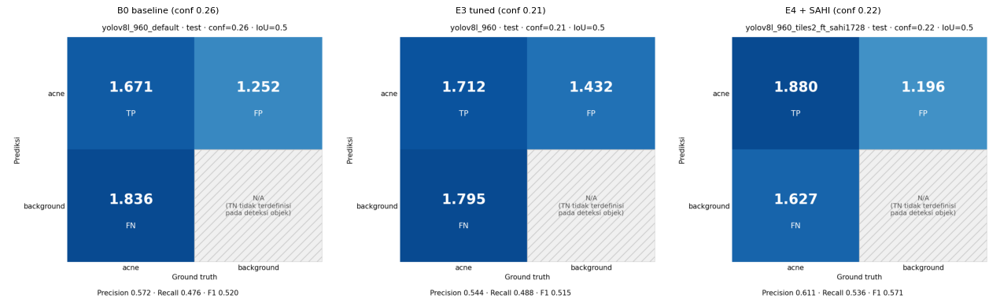

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.9))
for ax, k in zip(axes, TABLE_ORDER):
    c = VARS[k]["m"]["conf_selected_on_val"]
    show_img(ax, cv2.imread(str(RUNS / "eval" / VARS[k]["eval"] / f"confusion_matrix_conf{c:.2f}.png")),
             f"{VARS[k]['label']} (conf {c:.2f})")
plt.tight_layout(); plt.show()

**Jenis false positive.** FP *lokalisasi* = overlap sebagian dengan lesi GT (0,1 ≤ IoU < 0,5,
kesalahan skala/posisi); FP *latar* = tanpa overlap (kulit, latar, atau lesi yang tidak dianotasi).

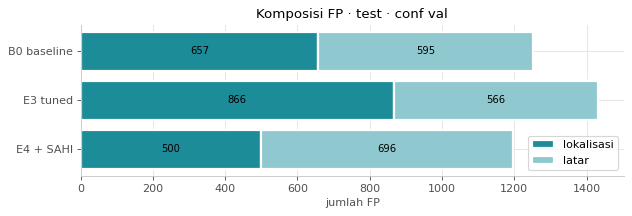

In [23]:
fpb = pd.DataFrame({VARS[k]["label"]: VARS[k]["m"]["test_conf_val_tuned"]["fp_breakdown"] for k in TABLE_ORDER}).T
fig, ax = plt.subplots(figsize=(8, 2.8))
left = np.zeros(len(fpb))
for col, colr, lab in [("localization", TEAL2, "lokalisasi"), ("background", TEAL3, "latar")]:
    bars = ax.barh(fpb.index, fpb[col], left=left, color=colr, label=lab, edgecolor="white", linewidth=2)
    ax.bar_label(bars, label_type="center", fontsize=9); left += fpb[col].to_numpy()
ax.invert_yaxis(); ax.legend(loc="lower right"); ax.set(title="Komposisi FP · test · conf val", xlabel="jumlah FP")
plt.tight_layout(); plt.show()

### 5.2 Kurva Precision-Recall Ultralytics (hanya mode plain; SAHI tidak lewat `model.val`)

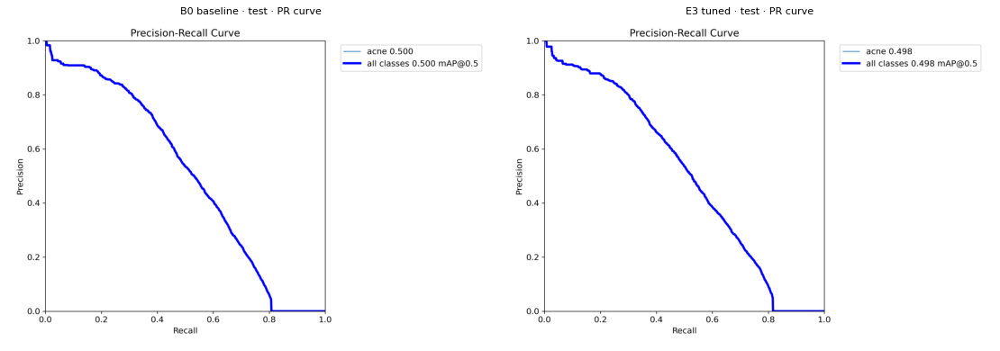

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, k in zip(axes, ["B0", "E3"]):
    show_img(ax, cv2.imread(str(RUNS / "eval" / VARS[k]["eval"] / "BoxPR_curve.png")), f"{VARS[k]['label']} · test · PR curve")
plt.tight_layout(); plt.show()

### 5.3 Per level keparahan (test, conf val)

F1                            MAE                   
varian B0 baseline E3 tuned E4 + SAHI B0 baseline E3 tuned E4 + SAHI
level                                                               
level0      0.5016   0.5071    0.5668        5.67     5.27      5.06
level1      0.5373   0.5280    0.5849        8.08     8.46      8.31
level2      0.5717   0.5483    0.6094        9.50     9.50      8.50
level3      0.3756   0.4118    0.4556      261.00   188.00    170.00

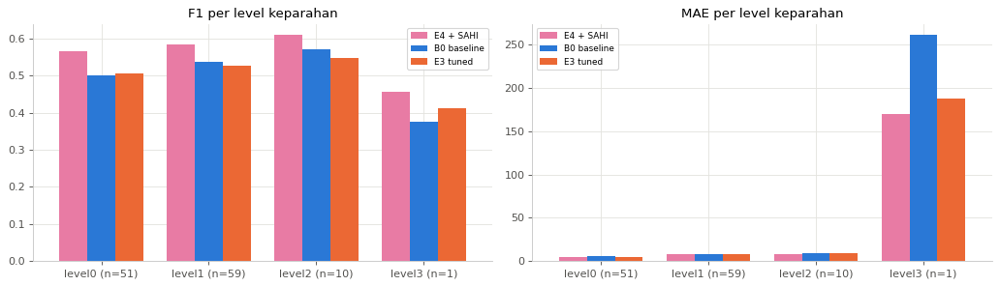

In [25]:
lv = []
for k in TABLE_ORDER:
    for L, v in VARS[k]["m"]["test_conf_val_tuned"]["per_level"].items():
        lv.append({"varian": VARS[k]["label"], "level": L, "Precision": v["detection"]["precision"],
                   "Recall": v["detection"]["recall"], "F1": v["detection"]["F1"],
                   "MAE": v["counting"]["MAE"], "n": v["counting"]["n_images"]})
lv = pd.DataFrame(lv)
display(lv.pivot(index="level", columns="varian", values=["F1", "MAE"])[[(a, VARS[k]["label"]) for a in ["F1", "MAE"] for k in TABLE_ORDER]])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, met in zip(axes, ["F1", "MAE"]):
    piv = lv.pivot(index="level", columns="varian", values=met)[[VARS[k]["label"] for k in CHART_ORDER]]
    n_lv = lv.drop_duplicates("level").set_index("level")["n"]
    piv.index = [f"{L} (n={n_lv[L]})" for L in piv.index]
    piv.plot.bar(ax=ax, color=[VARS[k]["color"] for k in CHART_ORDER], rot=0, width=0.78)
    ax.set(title=f"{met} per level keparahan", xlabel="")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.4 Kecepatan inferensi
- **Latency end-to-end**: median per gambar test termasuk baca gambar (gambar pertama = warmup, diabaikan),
  RTX 4060, dari `metrics.json → latency_ms_median`.
- **Model-only**: `speed["inference"]` dari `model.val` Ultralytics (tidak tersedia untuk SAHI).

,latency end-to-end (ms),model-only Ultralytics (ms),F1
B0 baseline,69.2,42.98,0.5198
E3 tuned,69.9,43.80,0.5148
E4 + SAHI,625.6,NaN,0.5712


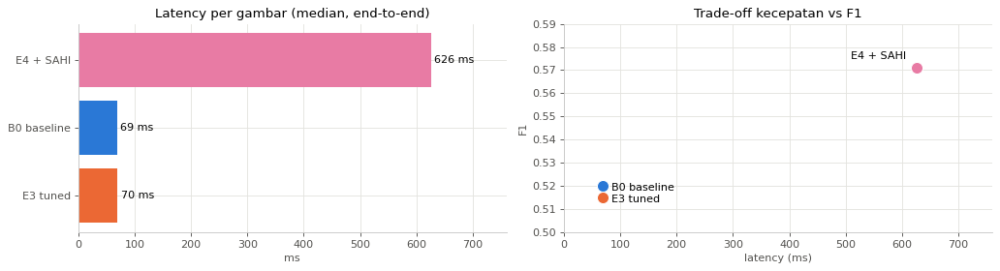

In [26]:
spd = pd.DataFrame({VARS[k]["label"]: {
    "latency end-to-end (ms)": VARS[k]["m"]["latency_ms_median"],
    "model-only Ultralytics (ms)": (VARS[k]["m"]["detection_test_ultralytics"] or {}).get("inference_ms"),
    "F1": VARS[k]["m"]["test_conf_val_tuned"]["detection"]["F1"]} for k in TABLE_ORDER}).T
display(spd)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
labs = [VARS[k]["label"] for k in CHART_ORDER]
bars = ax[0].barh(labs, spd.loc[labs, "latency end-to-end (ms)"], color=[VARS[k]["color"] for k in CHART_ORDER])
ax[0].bar_label(bars, fmt="%.0f ms", padding=3); ax[0].invert_yaxis()
ax[0].set(title="Latency per gambar (median, end-to-end)", xlabel="ms"); ax[0].set_xlim(0, 760)
for k in CHART_ORDER:
    ax[1].scatter(spd.loc[VARS[k]["label"], "latency end-to-end (ms)"], spd.loc[VARS[k]["label"], "F1"],
                  s=120, color=VARS[k]["color"], edgecolor="white", zorder=3)
    ax[1].annotate(VARS[k]["label"], (spd.loc[VARS[k]["label"], "latency end-to-end (ms)"], spd.loc[VARS[k]["label"], "F1"]),
                   xytext=(-10, 8) if k == "E4S" else (8, -4), textcoords="offset points", ha="right" if k == "E4S" else "left")
ax[1].set(title="Trade-off kecepatan vs F1", xlabel="latency (ms)", ylabel="F1", xlim=(0, 760), ylim=(0.50, 0.59))
plt.tight_layout(); plt.show()

### 5.5 Uji signifikansi (bootstrap per gambar)
Selisih metrik dengan interval kepercayaan 95% dari resampling gambar test (`docs/report/bootstrap.json`).
Interval yang tidak memuat 0 → beda signifikan. ΔMAE negatif = varian pertama lebih baik.

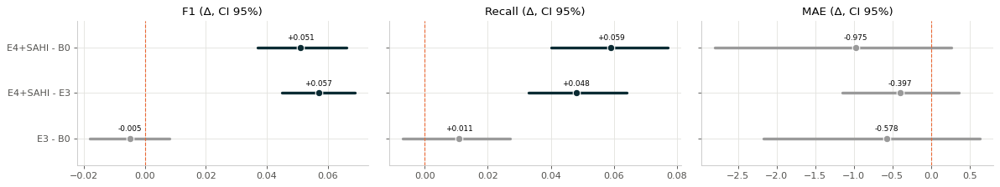

,dMAE,dF1,dRecall
E4+SAHI - B0,"-0.975 [-2.802, +0.264]","+0.051 [+0.037, +0.066]","+0.059 [+0.040, +0.077]"
E4+SAHI - E3,"-0.397 [-1.149, +0.364]","+0.057 [+0.045, +0.069]","+0.048 [+0.033, +0.064]"
E3 - B0,"-0.578 [-2.174, +0.636]","-0.005 [-0.018, +0.008]","+0.011 [-0.007, +0.027]"


In [27]:
boot = json.loads((REPORT / "bootstrap.json").read_text())
pairs = ["E4+SAHI - B0", "E4+SAHI - E3", "E3 - B0"]
fig, axes = plt.subplots(1, 3, figsize=(15, 2.9), sharey=True)
for ax, met in zip(axes, ["dF1", "dRecall", "dMAE"]):
    for i, p in enumerate(pairs):
        est, lo, hi = boot[p][met]
        sig = not (lo <= 0 <= hi)
        ax.plot([lo, hi], [i, i], color=TEAL if sig else "#9a9a9a", lw=3, solid_capstyle="round")
        ax.scatter(est, i, color=TEAL if sig else "#9a9a9a", s=60, zorder=3, edgecolor="white")
        ax.annotate(f"{est:+.3f}", (est, i), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
    ax.axvline(0, color="#eb6834", lw=1, ls="--"); ax.set_title(met[1:] + " (Δ, CI 95%)")
axes[0].set_yticks(range(len(pairs)), pairs); axes[0].invert_yaxis(); axes[0].set_ylim(2.6, -0.6)
plt.tight_layout(); plt.show()
pd.DataFrame({p: {m: f"{v[0]:+.3f} [{v[1]:+.3f}, {v[2]:+.3f}]" for m, v in boot[p].items()} for p in pairs}).T

### 5.6 Desain 2×2: bobot awal × fine-tune tile (E5)

E4 di-fine-tune dari E3, sehingga keunggulan E4 + SAHI atas B0 mencampur dua faktor: **tuning E3** dan
**fine-tune tile**. **E5** memakai config E4 persis (`configs/yolov8l_960_default_tiles2_ft.yaml`), hanya
bobot awalnya B0. Empat sel desain (semua inferensi SAHI 1728, test, conf dipilih di val):

| | tanpa fine-tune tile | dengan fine-tune tile |
|---|---|---|
| **bobot awal B0** | B0 + SAHI | E5 + SAHI |
| **bobot awal E3** | E3 + SAHI | E4 + SAHI |

Versi plain (tanpa SAHI) ikut ditampilkan untuk melihat efek fine-tune tile pada gambar utuh 960.

In [28]:
# (init, tile-FT, inferensi) -> run eval
ABL = {("B0", "tidak", "plain"): "yolov8l_960_default", ("B0", "ya", "plain"): "yolov8l_960_default_tiles2_ft",
       ("E3", "tidak", "plain"): "yolov8l_960",         ("E3", "ya", "plain"): "yolov8l_960_tiles2_ft",
       ("B0", "tidak", "SAHI"): "yolov8l_960_default_sahi1728", ("B0", "ya", "SAHI"): "yolov8l_960_default_tiles2_ft_sahi1728",
       ("E3", "tidak", "SAHI"): "yolov8l_960_sahi1728",         ("E3", "ya", "SAHI"): "yolov8l_960_tiles2_ft_sahi1728"}
NAME = {("B0", "tidak"): "B0", ("B0", "ya"): "E5", ("E3", "tidak"): "E3", ("E3", "ya"): "E4"}
rows = []
for (init, ft, inf), run in ABL.items():
    m = json.loads((RUNS / "eval" / run / "metrics.json").read_text()); t = m["test_conf_val_tuned"]
    rows.append({"varian": NAME[init, ft] + (" + SAHI" if inf == "SAHI" else ""), "bobot awal": init,
                 "fine-tune tile": ft, "inferensi": inf, "conf (val)": m["conf_selected_on_val"],
                 "Precision": t["detection"]["precision"], "Recall": t["detection"]["recall"],
                 "F1": t["detection"]["F1"], "mAP@50": m["ap50_test_internal"],
                 "mAP@50-95": m["map50_95_test_internal"], "MAE": t["counting"]["MAE"]})
abl = pd.DataFrame(rows).set_index("varian")
abl.style.format(precision=4).highlight_max(subset=["Precision", "Recall", "F1", "mAP@50", "mAP@50-95"], color="#fde2dd") \
   .highlight_min(subset=["MAE"], color="#fde2dd")

,bobot awal,fine-tune tile,inferensi,conf (val),Precision,Recall,F1,mAP@50,mAP@50-95,MAE
varian,,,,,,,,,,
B0,B0,tidak,plain,0.2600,0.5717,0.4765,0.5198,0.4994,0.1923,9.2700
E5,B0,ya,plain,0.2200,0.5248,0.4676,0.4946,0.4704,0.1752,9.3700
E3,E3,tidak,plain,0.2100,0.5445,0.4882,0.5148,0.4909,0.1863,8.6900
E4,E3,ya,plain,0.2200,0.5251,0.4953,0.5098,0.4895,0.1897,8.4500
B0 + SAHI,B0,tidak,SAHI,0.3400,0.5685,0.4876,0.5249,0.5113,0.1903,10.0400
E5 + SAHI,B0,ya,SAHI,0.2200,0.5982,0.5158,0.5540,0.5333,0.1919,8.8300
E3 + SAHI,E3,tidak,SAHI,0.2300,0.5925,0.5341,0.5618,0.5370,0.1945,8.3300
E4 + SAHI,E3,ya,SAHI,0.2200,0.6112,0.5361,0.5712,0.5499,0.2046,8.2900


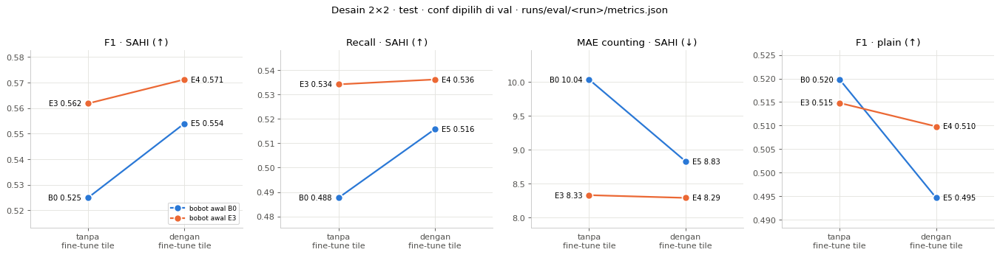

In [29]:
# Plot interaksi: garis = bobot awal (biru B0, oranye E3, warna sama dengan bagian lain), x = fine-tune tile
INIT_COLOR = {"B0": VARS["B0"]["color"], "E3": VARS["E3"]["color"]}
panels = [("F1", "SAHI", "F1 · SAHI (↑)"), ("Recall", "SAHI", "Recall · SAHI (↑)"),
          ("MAE", "SAHI", "MAE counting · SAHI (↓)"), ("F1", "plain", "F1 · plain (↑)")]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, (met, inf, title) in zip(axes, panels):
    for init in ["B0", "E3"]:
        sub = abl[(abl["bobot awal"] == init) & (abl["inferensi"] == inf)].set_index("fine-tune tile").loc[["tidak", "ya"]]
        ax.plot([0, 1], sub[met], "-o", color=INIT_COLOR[init], lw=2, ms=9, mec="white", mew=1.5, label=f"bobot awal {init}")
        for x, (name, v) in enumerate(zip(sub.index.map(lambda f: NAME[init, f]), sub[met])):
            ax.annotate(f"{name} {v:.3f}" if met != "MAE" else f"{name} {v:.2f}", (x, v), xytext=(-8 if x == 0 else 8, 0),
                        textcoords="offset points", ha="right" if x == 0 else "left", va="center", fontsize=9)
    ax.set_xticks([0, 1], ["tanpa\nfine-tune tile", "dengan\nfine-tune tile"]); ax.set_xlim(-0.6, 1.6)
    ax.margins(y=0.25); ax.set_title(title)
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Desain 2×2 · test · conf dipilih di val · runs/eval/<run>/metrics.json", y=1.02)
plt.tight_layout(); plt.show()

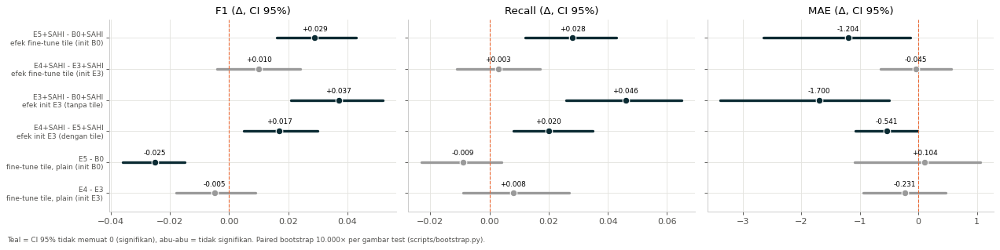

In [30]:
pairs2 = ["E5+SAHI - B0+SAHI", "E4+SAHI - E3+SAHI", "E3+SAHI - B0+SAHI", "E4+SAHI - E5+SAHI", "E5 - B0", "E4 - E3"]
desc = ["efek fine-tune tile (init B0)", "efek fine-tune tile (init E3)", "efek init E3 (tanpa tile)",
        "efek init E3 (dengan tile)", "fine-tune tile, plain (init B0)", "fine-tune tile, plain (init E3)"]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, met in zip(axes, ["dF1", "dRecall", "dMAE"]):
    for i, p in enumerate(pairs2):
        est, lo, hi = boot[p][met]          # boot dimuat di 5.5
        sig = not (lo <= 0 <= hi)
        ax.plot([lo, hi], [i, i], color=TEAL if sig else "#9a9a9a", lw=3, solid_capstyle="round")
        ax.scatter(est, i, color=TEAL if sig else "#9a9a9a", s=60, zorder=3, edgecolor="white")
        ax.annotate(f"{est:+.3f}", (est, i), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
    ax.axvline(0, color="#eb6834", lw=1, ls="--"); ax.set_title(met[1:] + " (Δ, CI 95%)")
axes[0].set_yticks(range(len(pairs2)), [f"{p}\n{d}" for p, d in zip(pairs2, desc)], fontsize=8)
axes[0].set_ylim(len(pairs2) - 0.4, -0.6)
fig.text(0.01, -0.03, "Teal = CI 95% tidak memuat 0 (signifikan), abu-abu = tidak signifikan. "
         "Paired bootstrap 10.000× per gambar test (scripts/bootstrap.py).", fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()

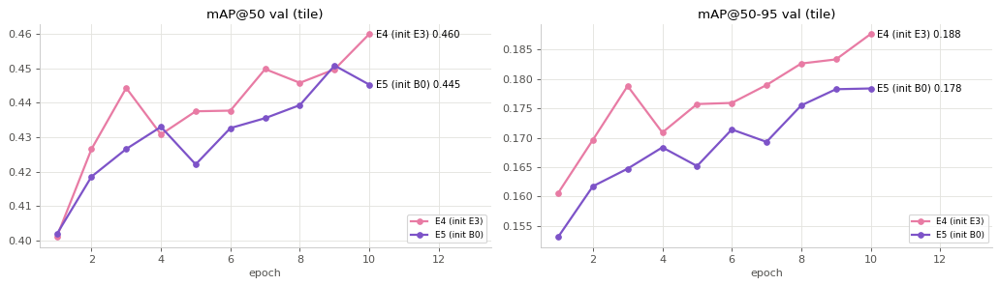

In [31]:
# Kurva training E4 vs E5: val keduanya = data_tiles2 (asli + tile), jadi sebanding satu sama lain,
# tetapi tidak sebanding dengan kurva B0/E3 di bagian 4.
FT = {"E4 (init E3)": ("yolov8l_960_tiles2_ft", VARS["E4S"]["color"]),
      "E5 (init B0)": ("yolov8l_960_default_tiles2_ft", "#7d53c8")}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, title in zip(axes, ["metrics/mAP50(B)", "metrics/mAP50-95(B)"], ["mAP@50 val (tile)", "mAP@50-95 val (tile)"]):
    for lab, (run, colr) in FT.items():
        r = pd.read_csv(RUNS / "detect" / run / "results.csv"); r.columns = r.columns.str.strip()
        ax.plot(r["epoch"], r[col], "-o", color=colr, lw=2, ms=5, label=lab)
        ax.annotate(f"{lab} {r[col].iloc[-1]:.3f}", (r["epoch"].iloc[-1], r[col].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=9)
    ax.set(title=title, xlabel="epoch", xlim=(0.5, 13.5)); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Fakta** (test, SAHI 1728, conf val; CI dari `docs/report/bootstrap.json`):
- **Fine-tune tile menolong B0** secara signifikan: E5 + SAHI − B0 + SAHI ΔF1 +0,029 [+0,016; +0,043],
  ΔMAE −1,20 [−2,65; −0,14]. Pada E3 efeknya kecil dan tidak signifikan (ΔF1 +0,010).
- **Bobot awal E3 tetap lebih baik**: E4 + SAHI − E5 + SAHI ΔF1 +0,017 [+0,005; +0,030]. Selisih init
  mengecil dari +0,037 (tanpa tile) menjadi +0,017 (dengan tile), jadi kedua faktor saling tumpang tindih.
- **Tanpa SAHI, fine-tune tile merugikan**: E5 − B0 ΔF1 −0,025 [−0,036; −0,015].

**Dugaan**: fine-tune pada tile menggeser model ke skala lesi yang dilihat SAHI (±2× lebih besar), sehingga
hanya cocok dipakai bersama SAHI. Semua hasil berasal dari satu seed.

## 6. Counting (jumlah lesi per gambar)

Jumlah prediksi di atas conf val dibandingkan jumlah lesi GT per gambar test
(`runs/eval/<run>/counts_test.csv`). Bias negatif = *under-count*.

,MAE,RMSE,bias,pearson_r,total_gt,total_pred
B0 baseline,9.27,25.99,-4.83,0.8604,3507.0,2923.0
E3 tuned,8.69,20.18,-3.00,0.9096,3507.0,3144.0
E4 + SAHI,8.29,18.66,-3.56,0.9425,3507.0,3076.0


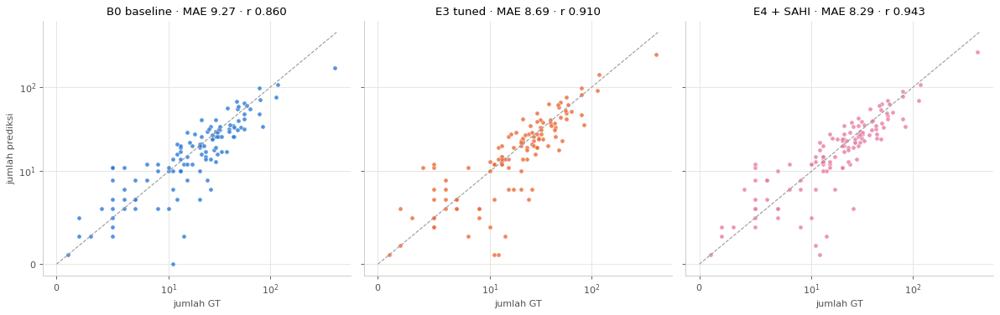

In [32]:
cnt = pd.DataFrame({VARS[k]["label"]: VARS[k]["m"]["test_conf_val_tuned"]["counting"] for k in TABLE_ORDER}).T
display(cnt[["MAE", "RMSE", "bias", "pearson_r", "total_gt", "total_pred"]])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
for ax, k in zip(axes, TABLE_ORDER):
    c = pd.read_csv(RUNS / "eval" / VARS[k]["eval"] / "counts_test.csv")
    lim = max(c.gt_count.max(), c.pred_count.max()) * 1.05
    ax.plot([0, lim], [0, lim], color="#9a9a9a", ls="--", lw=1)
    ax.scatter(c.gt_count, c.pred_count, s=22, color=VARS[k]["color"], alpha=.8, edgecolor="white", linewidth=.5)
    m = cnt.loc[VARS[k]["label"]]
    ax.set(title=f"{VARS[k]['label']} · MAE {m.MAE:.2f} · r {m.pearson_r:.3f}", xlabel="jumlah GT")
    ax.set_xscale("symlog", linthresh=10); ax.set_yscale("symlog", linthresh=10)
axes[0].set_ylabel("jumlah prediksi")
plt.tight_layout(); plt.show()

## 7. Hasil inferensi pada gambar test

Gambar dari `scripts/predict.py --compare` (`runs/predict/<run>/test/`): **biru = TP**, **kuning = FP**,
**merah = FN** (lesi terlewat). Threshold conf = conf val masing-masing varian.

,TP predict,TP evaluate,FP predict,FP evaluate
B0 baseline,1671,1671,1252,1252
E3 tuned,1712,1712,1432,1432
E4 + SAHI,1880,1880,1196,1196


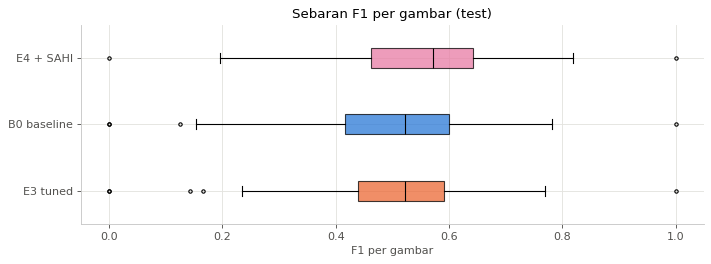

In [33]:
pc = {k: pd.read_csv(RUNS / "predict" / VARS[k]["pred"] / "test" / "predictions.csv").set_index("image") for k in TABLE_ORDER}
f1 = pd.DataFrame({k: 2 * p.TP / (2 * p.TP + p.FP + p.FN).replace(0, np.nan) for k, p in pc.items()})
f1["n_gt"] = pc["B0"]["gt_count"]
# Konsistensi: total TP/FP/FN predict.py harus sama dengan evaluate.py (threshold sama)
chk = pd.DataFrame({VARS[k]["label"]: {"TP predict": p.TP.sum(), "TP evaluate": VARS[k]["m"]["test_conf_val_tuned"]["detection"]["TP"],
                                         "FP predict": p.FP.sum(), "FP evaluate": VARS[k]["m"]["test_conf_val_tuned"]["detection"]["FP"]}
                    for k, p in pc.items()}).T
display(chk)

fig, ax = plt.subplots(figsize=(9, 3.4))
dd = [f1[k].dropna() for k in CHART_ORDER]
bp = ax.boxplot(dd, labels=[VARS[k]["label"] for k in CHART_ORDER], vert=False, patch_artist=True,
                medianprops=dict(color="black"), flierprops=dict(ms=3))
for patch, k in zip(bp["boxes"], CHART_ORDER):
    patch.set_facecolor(VARS[k]["color"]); patch.set_alpha(.75)
ax.invert_yaxis(); ax.set(title="Sebaran F1 per gambar (test)", xlabel="F1 per gambar")
plt.tight_layout(); plt.show()

### 7.1 Perbandingan tiga varian pada gambar yang sama

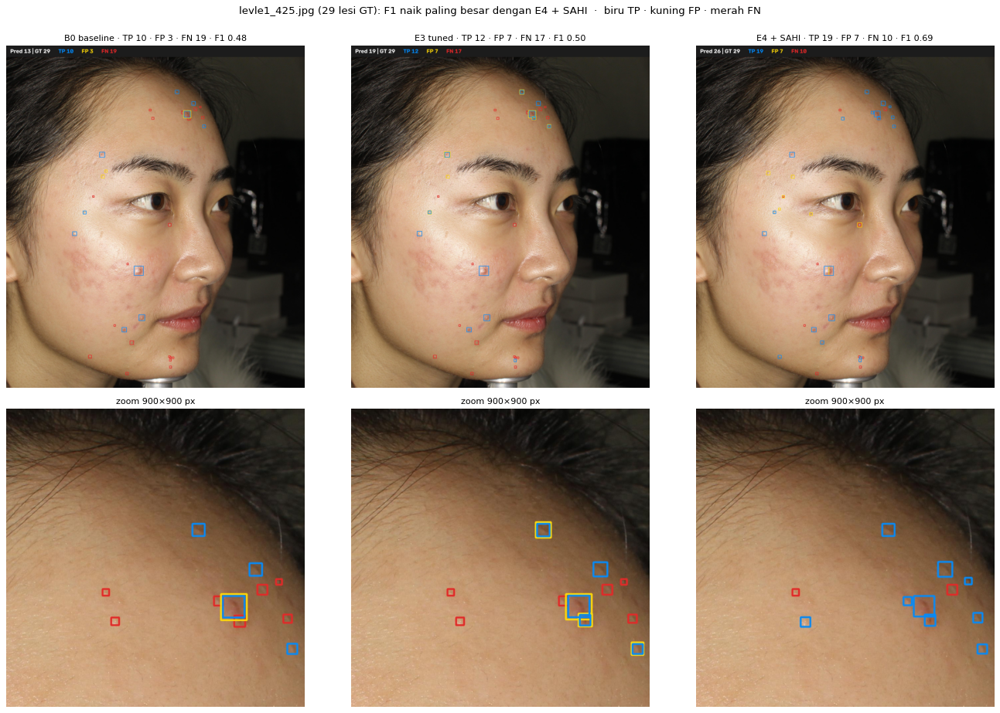

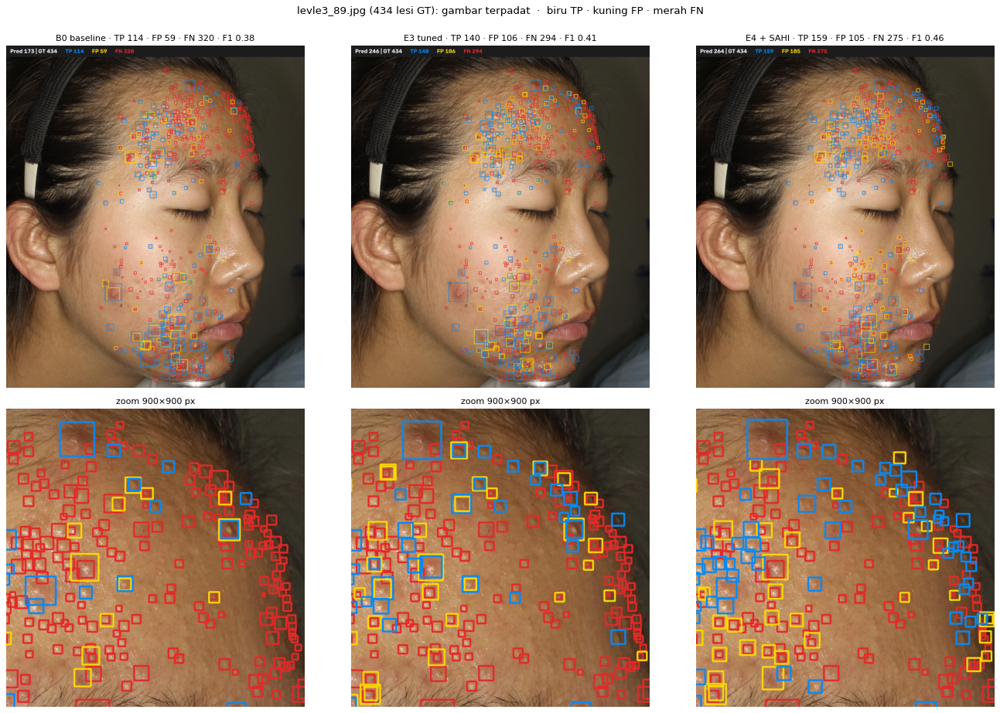

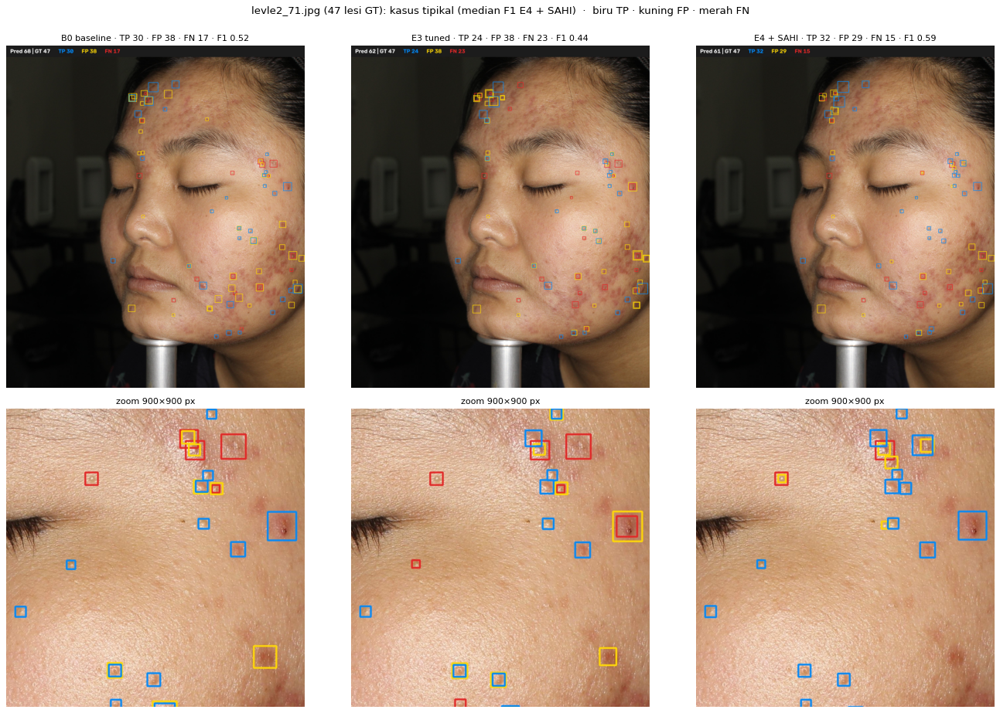

In [34]:
sel = f1[f1["n_gt"] >= 20].copy()
sel["gain"] = sel["E4S"] - sel[["B0", "E3"]].max(axis=1)
picks = {"F1 naik paling besar dengan E4 + SAHI": sel["gain"].idxmax(),
         "gambar terpadat": f1["n_gt"].idxmax(),
         "kasus tipikal (median F1 E4 + SAHI)": (sel["E4S"] - sel["E4S"].median()).abs().idxmin()}
for why, img_name in picks.items():
    orig = cv2.imread(str(DATA / "images" / "test" / img_name))
    gt = load_gt_boxes(DATA / "labels" / "test" / f"{Path(img_name).stem}.txt", orig.shape[1], orig.shape[0])
    # Area zoom: jendela 900 px (langkah 100 px) yang memuat pusat lesi GT terbanyak
    ctr = (gt[:, :2] + gt[:, 2:]) / 2
    cands = [(x, y) for x in range(0, orig.shape[1] - 899, 100) for y in range(0, orig.shape[0] - 899, 100)]
    zx, zy = max(cands, key=lambda p: ((ctr[:, 0] >= p[0]) & (ctr[:, 0] < p[0] + 900) &
                                      (ctr[:, 1] >= p[1]) & (ctr[:, 1] < p[1] + 900)).sum())
    fig, axes = plt.subplots(2, 3, figsize=(17, 11.5), gridspec_kw={"height_ratios": [1.15, 1]})
    for j, k in enumerate(TABLE_ORDER):
        p = pc[k].loc[img_name].astype(int)
        ann = cv2.imread(str(RUNS / "predict" / VARS[k]["pred"] / "test" / img_name))
        hdr = ann.shape[0] - orig.shape[0]                 # strip header predict.py di atas foto
        show_img(axes[0, j], ann, f"{VARS[k]['label']} · TP {p.TP} · FP {p.FP} · FN {p.FN} · F1 {f1.loc[img_name, k]:.2f}", max_side=1100)
        show_img(axes[1, j], ann[hdr + zy:hdr + zy + 900, zx:zx + 900], "zoom 900×900 px")
    fig.suptitle(f"{img_name} ({int(f1.loc[img_name, 'n_gt'])} lesi GT): {why}  ·  biru TP · kuning FP · merah FN",
                 fontsize=12, y=1.0)
    plt.tight_layout(); plt.show()

### 7.2 Inferensi langsung (opsional, butuh GPU)
Set `RUN_INFERENCE = True` untuk menjalankan E4 + SAHI pada satu gambar. Hasil identik dengan
`scripts/predict.py`; untuk satu folder penuh tetap pakai script tersebut.

In [35]:
RUN_INFERENCE = False
IMAGE = DATA / "images" / "test" / "levle2_118.jpg"

if RUN_INFERENCE:
    from sahi import AutoDetectionModel
    from sahi.predict import get_sliced_prediction
    import time
    w = RUNS / "detect" / VARS["E4S"]["det"] / "weights" / "best.pt"
    conf = VARS["E4S"]["m"]["conf_selected_on_val"]
    sm = AutoDetectionModel.from_pretrained(model_type="ultralytics", model_path=str(w), confidence_threshold=conf,
                                            image_size=960, device="cuda:0")
    t0 = time.perf_counter()
    r = get_sliced_prediction(str(IMAGE), sm, slice_height=1728, slice_width=1728, overlap_height_ratio=0.2,
                              overlap_width_ratio=0.2, postprocess_type="NMS", postprocess_match_metric="IOU",
                              postprocess_match_threshold=0.5, verbose=0)
    ms = (time.perf_counter() - t0) * 1000
    img = cv2.imread(str(IMAGE))
    boxes = np.array([p.bbox.to_xyxy() for p in r.object_prediction_list]).reshape(-1, 4)
    gt = load_gt_boxes(DATA / "labels" / "test" / f"{IMAGE.stem}.txt", img.shape[1], img.shape[0])
    fig, ax = plt.subplots(figsize=(9, 8))
    show_img(ax, draw_gt(img, boxes, (255, 140, 0)), f"E4 + SAHI · {len(boxes)} prediksi (GT {len(gt)}) · {ms:.0f} ms")
    plt.show()
else:
    print("Lewati inferensi langsung (RUN_INFERENCE = False). Hasil prediksi tersimpan dipakai di 7.1.")

Lewati inferensi langsung (RUN_INFERENCE = False). Hasil prediksi tersimpan dipakai di 7.1.


## 8. Kesimpulan

**Fakta terverifikasi** (test, `imgsz=960`, IoU 0,5, conf dipilih di val; tabel di bagian 5–6):
- **E4 + SAHI** unggul di Precision, Recall, F1, mAP@50, dan mAP@50-95 dibanding B0 dan E3, dan
  kenaikan F1/Recall-nya signifikan secara statistik (CI 95% bootstrap tidak memuat 0).
- **E3 vs B0**: tuning augmentasi + hyperparameter saja tidak memberi beda F1 yang signifikan; MAE dan
  korelasi counting membaik, tetapi CI ΔMAE masih memuat 0.
- Perbaikan terbesar datang dari **resolusi efektif** (tiling saat training + SAHI saat inferensi), sesuai
  diagnosis bahwa mayoritas lesi < 16 px pada input 960.
- **Desain 2×2 (E5, bagian 5.6)**: fine-tune tile dari B0 juga menaikkan F1 + SAHI secara signifikan
  (+0,029), tetapi E4 (dari E3) tetap lebih baik (+0,017). Bobot hasil fine-tune tile hanya cocok untuk SAHI.
- Harga yang dibayar: SAHI ±9× lebih lambat (±626 ms vs ±70 ms per gambar pada RTX 4060).

**Keterbatasan**
- Satu kelas `acne` (tanpa tipe lesi); anotasi lingkaran → kotak menambah ketidakpastian lokalisasi
  (mAP@50-95 rendah, ±0,19–0,21).
- Test set kecil (121 gambar); per level keparahan jumlah gambarnya lebih kecil lagi.
- Sebagian FP latar kemungkinan lesi yang tidak dianotasi (dugaan, belum diverifikasi manual).